In [1]:
import matlab.engine

In [2]:
eng = matlab.engine.start_matlab()

In [3]:
s = eng.genpath("/home/kushal/repos/NMFLibrary/")
eng.addpath(s, nargout=0)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [5]:
%matplotlib inline

In [6]:
from pathlib import Path
import os
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [7]:
import pandas as pd
from data_lib.data_lib import config, SeriesAccessor, DataFrameAccessor

In [8]:
config.set_parent_path("/home/kushal/repos/td-svd-sandbox/data_lib/")

In [9]:
df = pd.read_csv("./data_lib/data/dataframe.csv")

In [10]:
df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,name,rect,kind,source,orig,symm_nmf,uuid
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,caiman-demo,NaN,soma,caiman,NaN,NaN,ca0d0779-4d51-44d8-8396-c3323422ff5b
1,1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,dendrites-1,1.0,dendrites,jason,NaN,NaN,70b87e26-ef67-40b5-97aa-1e2b710927ce
2,2,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,cortex-dendrites,1.0,crazy,andrea-tolias,NaN,NaN,4d827dd4-f18f-4eb7-95e9-7e3ad23544b6
3,3,3.0,3.0,3.0,3.0,3.0,3.0,3.0,NaN,NaN,NaN,cortex-dendrites,2.0,crazy,andrea-tolias,NaN,NaN,ffdd40c5-6fce-4218-9b3f-d5836ac89464
4,4,4.0,4.0,4.0,4.0,4.0,4.0,4.0,NaN,NaN,NaN,cortex-dendrites,3.0,crazy,andrea-tolias,NaN,NaN,99ec6c6f-8cd0-4eca-a7b3-8a20edb0e8eb
5,5,5.0,5.0,5.0,5.0,5.0,NaN,NaN,NaN,NaN,NaN,sue-movie,NaN,soma,caiman,NaN,NaN,2762373e-ca08-469f-a04f-f9ed9e9b80e2
6,6,6.0,6.0,6.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,drg,1.0,drg,drg-person,NaN,NaN,659dab9d-18f8-40b8-aae4-91fb0b6332a1
7,7,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,drg-gaussian-derivative,1.0,drg,drg-person,NaN,NaN,f1c2e96e-61de-4d86-bf71-e1118f8803d5
8,8,8.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vaz-1,1.0,soma-cortex,flynn-rockefeller,NaN,NaN,e1e70b61-beb6-463a-b09f-635791eab650
9,9,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vaz-1-subsample,1.0,soma-cortex,flynn-rockefeller,NaN,NaN,ebccff3e-314a-45f7-9e33-77ff3d0df6db


In [ ]:
indices = [0, 1, 4, 5, 6, 7, -1, -2]

In [195]:
ix = -1

In [196]:
movie = df.iloc[ix].lib.load_movie()
movie.shape

(1730, 75, 70)

In [197]:
uid = df.iloc[ix]["uuid"]

RFBOutputContext()

JupyterWgpuCanvas()
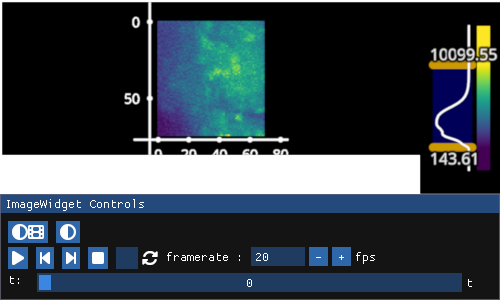

In [198]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
iw_movie.show()

In [199]:
unvec = UnVectorizer(movie.shape[1:])

In [200]:
movie.shape

(1730, 75, 70)

In [201]:
def load_symm_nmf(index: int):
    uid = df.iloc[index]["uuid"]
    out = list()
    for n in ["D", "A", "W"]:
        out.append(np.load(config.PARENT_PATH.joinpath(uid, "symm_nmf", f"{n}.npy")))
        
    return out

In [202]:
D, A, W = load_symm_nmf(ix)

RFBOutputContext()

JupyterWgpuCanvas(css_height='1200px', css_width='1100px')
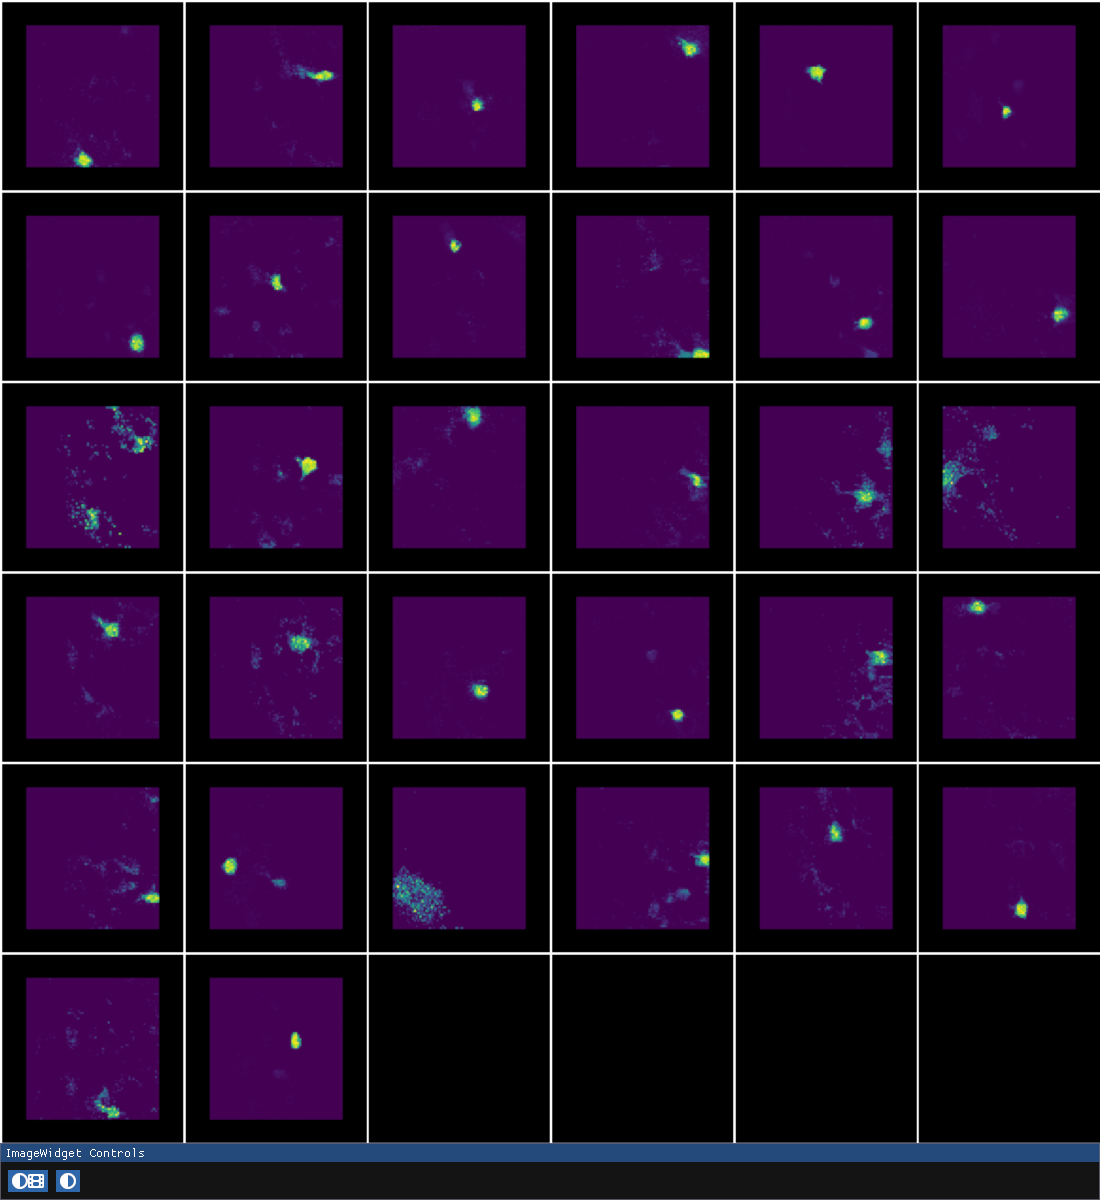

In [203]:
iw_s = fpl.ImageWidget([a for a in unvec.transform(W)], cmap="viridis", histogram_widget=False, figure_kwargs={"size": (1100, 1200)})
for sp in iw_s.figure:
    sp.toolbar = False
    sp.axes.visible = False
    sp.camera.zoom = 0.98
for g in iw_s.managed_graphics:
    g.vmin = np.percentile(g.data[:], 90)
    
iw_s.show()

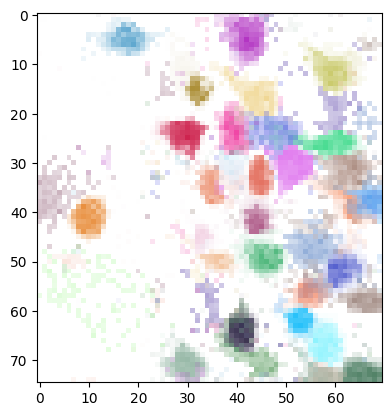

In [204]:
for a in unvec.transform(W):
    c = np.zeros((*a.shape, 4))
    rows, cols = np.where(a > np.percentile(a, 98))
    c[rows, cols, :-1] = np.random.rand(3)
    c[rows, cols, -1] = a[rows, cols]
    plt.imshow(c)